# 03: Exploratory Data Analysis (Phase 3)
**Uxbridge Lounge, Jan 2025 to Jun 2026, 13,046 clean rows**

Goal: understand what drives sales, waste and stockouts BEFORE building a model.
Every chart is saved to `docs/figures/` for the report and slides.

💼 Pro rule used throughout: for statistics, we add up to **one row per day** first.
The 24 menu items on the same day share the same weather and festival, so treating
them as 24 separate "samples" would make results look more certain than they are.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # let the notebook find the src/ folder

import matplotlib.pyplot as plt  # charts
import pandas as pd  # tables
import seaborn as sns  # nicer charts
from scipy import stats  # hypothesis tests

from src import config
from src.data_cleaning import load_clean
from src.features import add_business_columns, add_features

sns.set_theme(style="whitegrid")  # clean chart style
FIG = config.FIGURES_DIR  # where charts are saved
FIG.mkdir(parents=True, exist_ok=True)

df = add_business_columns(add_features(load_clean()))  # clean data + money columns
daily = df.groupby(["date", "day_of_week", "weather", "festival", "is_cricket"], as_index=False).agg(
    sold=("sold_qty", "sum"), revenue=("revenue_gbp", "sum"), waste_cost=("waste_cost_gbp", "sum"))  # one row per day
print(df.shape, daily.shape)

(13046, 27) (545, 8)


## 3.1 Sales by day of week

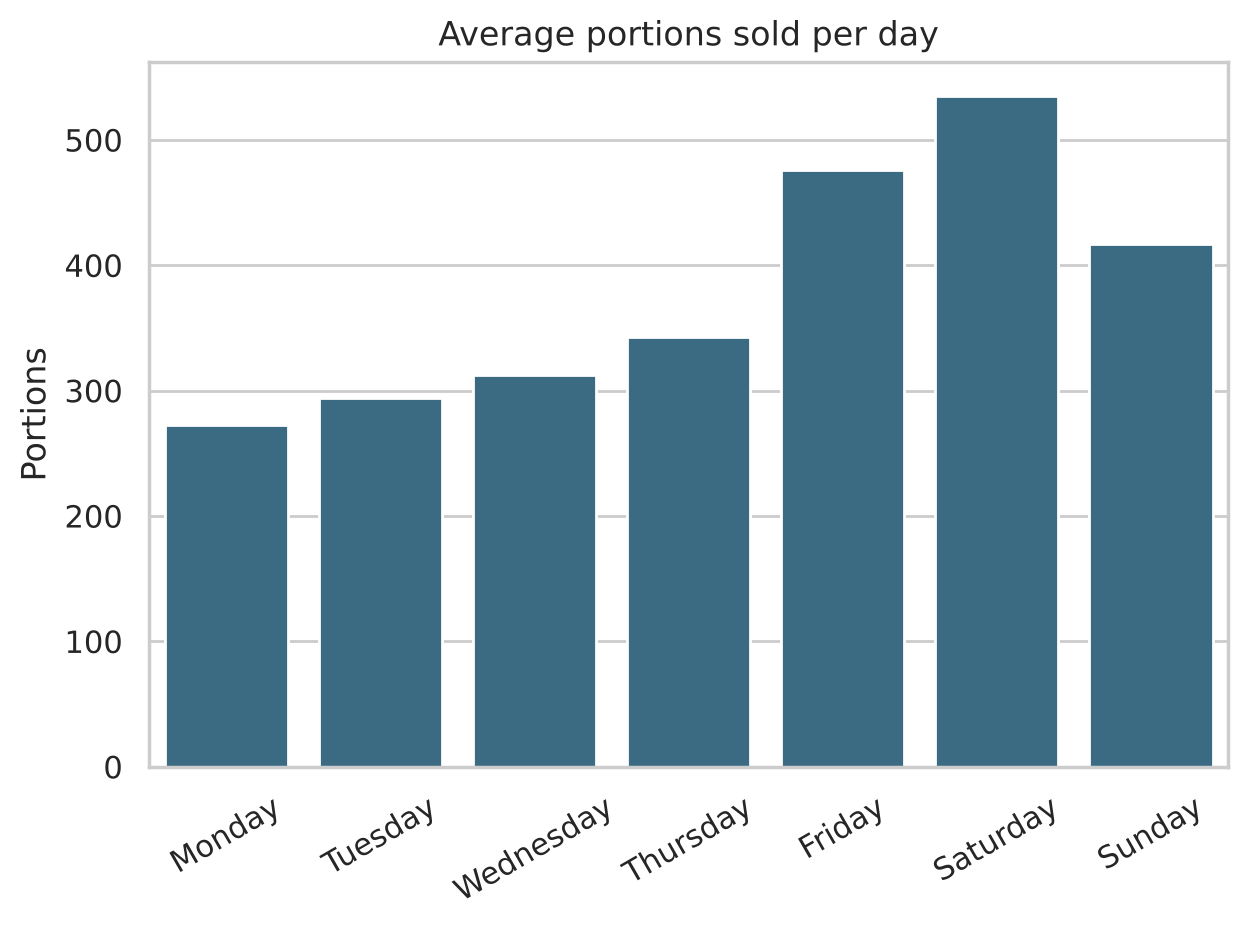

day_of_week
Monday       273.0
Tuesday      294.0
Wednesday    312.0
Thursday     343.0
Friday       476.0
Saturday     535.0
Sunday       417.0
Name: sold, dtype: float64

In [2]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ax = sns.barplot(data=daily, x="day_of_week", y="sold", order=order, color="#2f6f8f", errorbar=None)
ax.set(title="Average portions sold per day", xlabel="", ylabel="Portions")
plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(FIG / "eda_day_of_week.png", dpi=120); plt.show()
daily.groupby("day_of_week")["sold"].mean().reindex(order).round(0)

## 3.2 Food vs drinks, and each cuisine

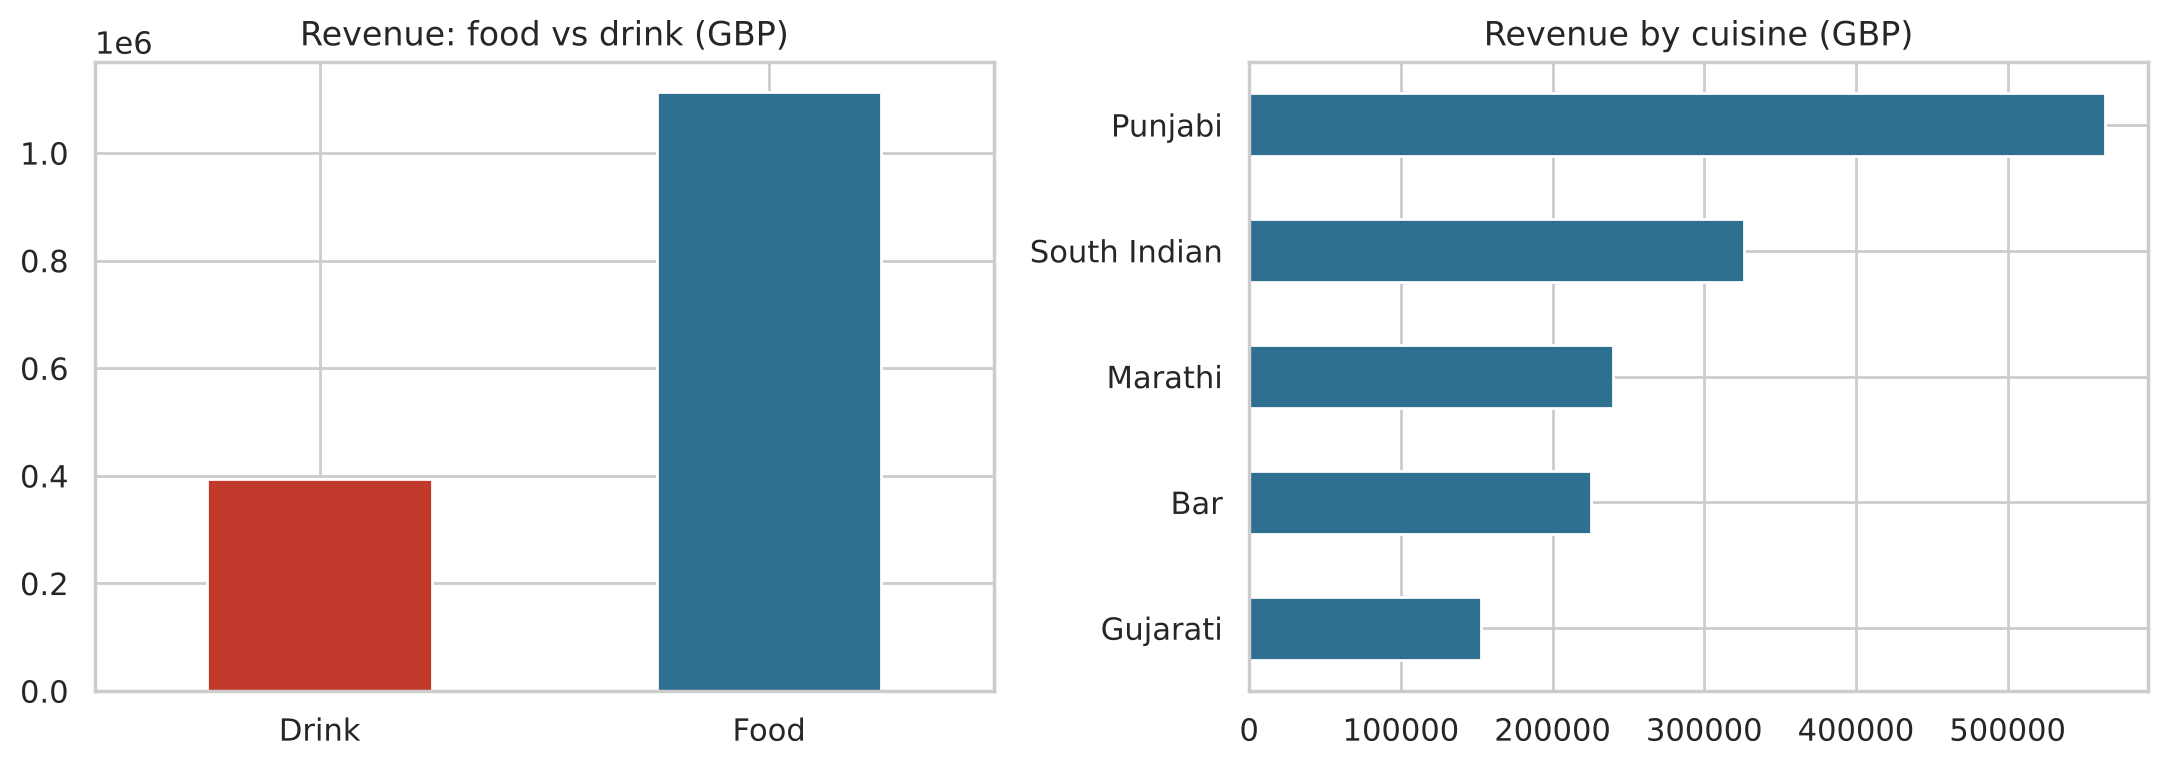

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.groupby("category")["revenue_gbp"].sum().plot.bar(ax=axes[0], color=["#c0392b", "#2f6f8f"], rot=0)
axes[0].set(title="Revenue: food vs drink (GBP)", xlabel="")
df.groupby("cuisine")["revenue_gbp"].sum().sort_values().plot.barh(ax=axes[1], color="#2f6f8f")
axes[1].set(title="Revenue by cuisine (GBP)", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_food_drink_cuisine.png", dpi=120); plt.show()

## 3.3 Weather and temperature

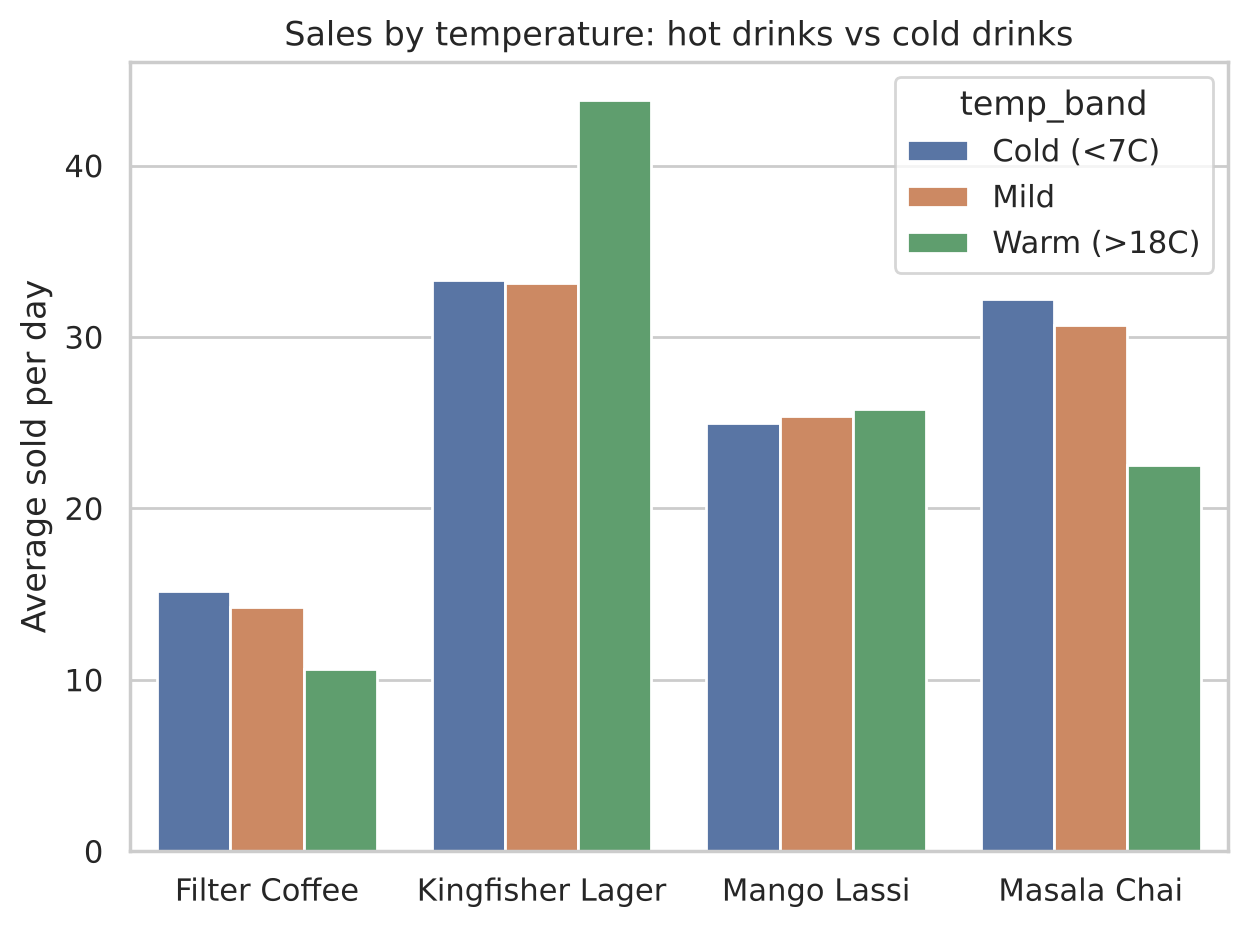

weather
Cloudy    395.0
Rainy     351.0
Snow      364.0
Sunny     389.0
Name: sold, dtype: float64

In [4]:
df["temp_band"] = pd.cut(df["temperature_c"], [-10, 7, 18, 35], labels=["Cold (<7C)", "Mild", "Warm (>18C)"])
items = ["Masala Chai", "Filter Coffee", "Mango Lassi", "Kingfisher Lager"]
ax = sns.barplot(data=df[df["item_name"].isin(items)], x="item_name", y="sold_qty", hue="temp_band", errorbar=None)
ax.set(title="Sales by temperature: hot drinks vs cold drinks", xlabel="", ylabel="Average sold per day")
plt.tight_layout(); plt.savefig(FIG / "eda_temperature.png", dpi=120); plt.show()
daily.groupby("weather")["sold"].mean().round(0)

## 3.4 Festivals and cricket

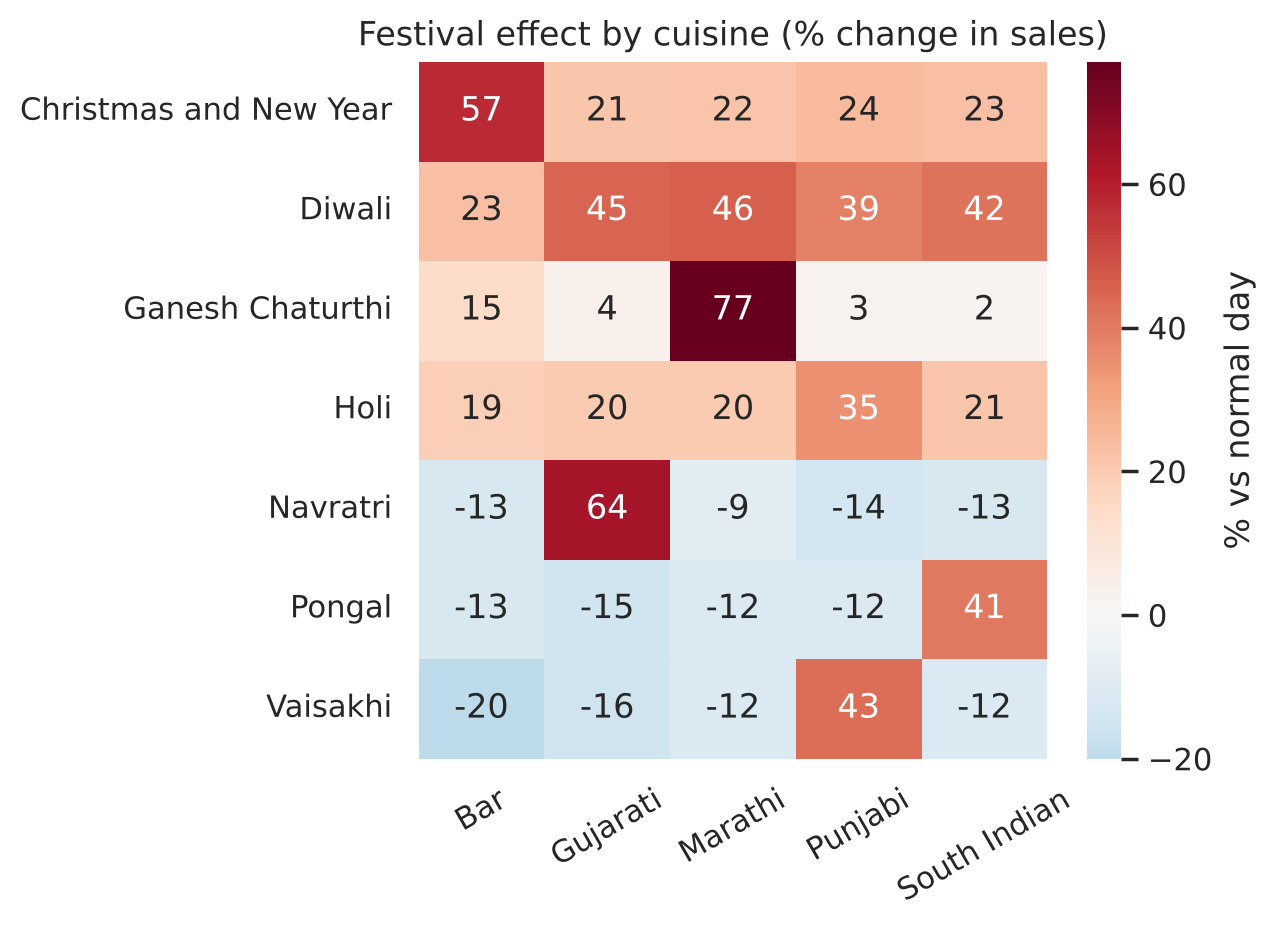

In [5]:
fest = df[df["festival"] != "None"].groupby(["festival", "cuisine"])["sold_qty"].mean().unstack()
normal = df[df["festival"] == "None"].groupby("cuisine")["sold_qty"].mean()
lift = (100 * (fest / normal - 1)).round(0)  # % more than a normal day
ax = sns.heatmap(lift, annot=True, fmt=".0f", cmap="RdBu_r", center=0, cbar_kws={"label": "% vs normal day"})
ax.set(title="Festival effect by cuisine (% change in sales)", xlabel="", ylabel="")
plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(FIG / "eda_festival_heatmap.png", dpi=120); plt.show()

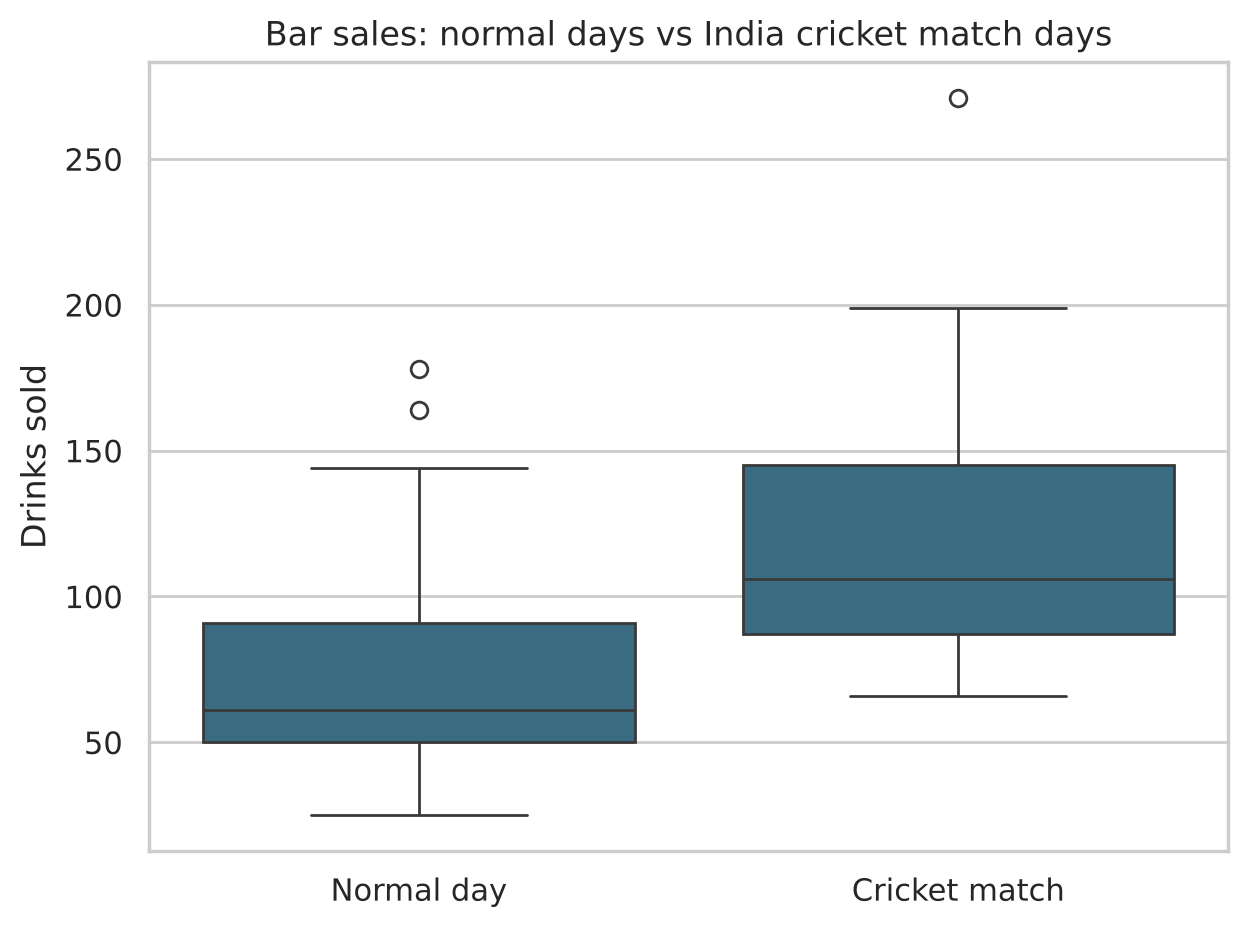

In [6]:
bar = df[df["cuisine"] == "Bar"].groupby(["date", "is_cricket"], as_index=False)["sold_qty"].sum()
ax = sns.boxplot(data=bar, x="is_cricket", y="sold_qty", color="#2f6f8f")
ax.set(title="Bar sales: normal days vs India cricket match days", xlabel="", ylabel="Drinks sold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal day", "Cricket match"])
plt.tight_layout(); plt.savefig(FIG / "eda_cricket.png", dpi=120); plt.show()

## 3.5 Waste (fresh items only, bottles don't go off)

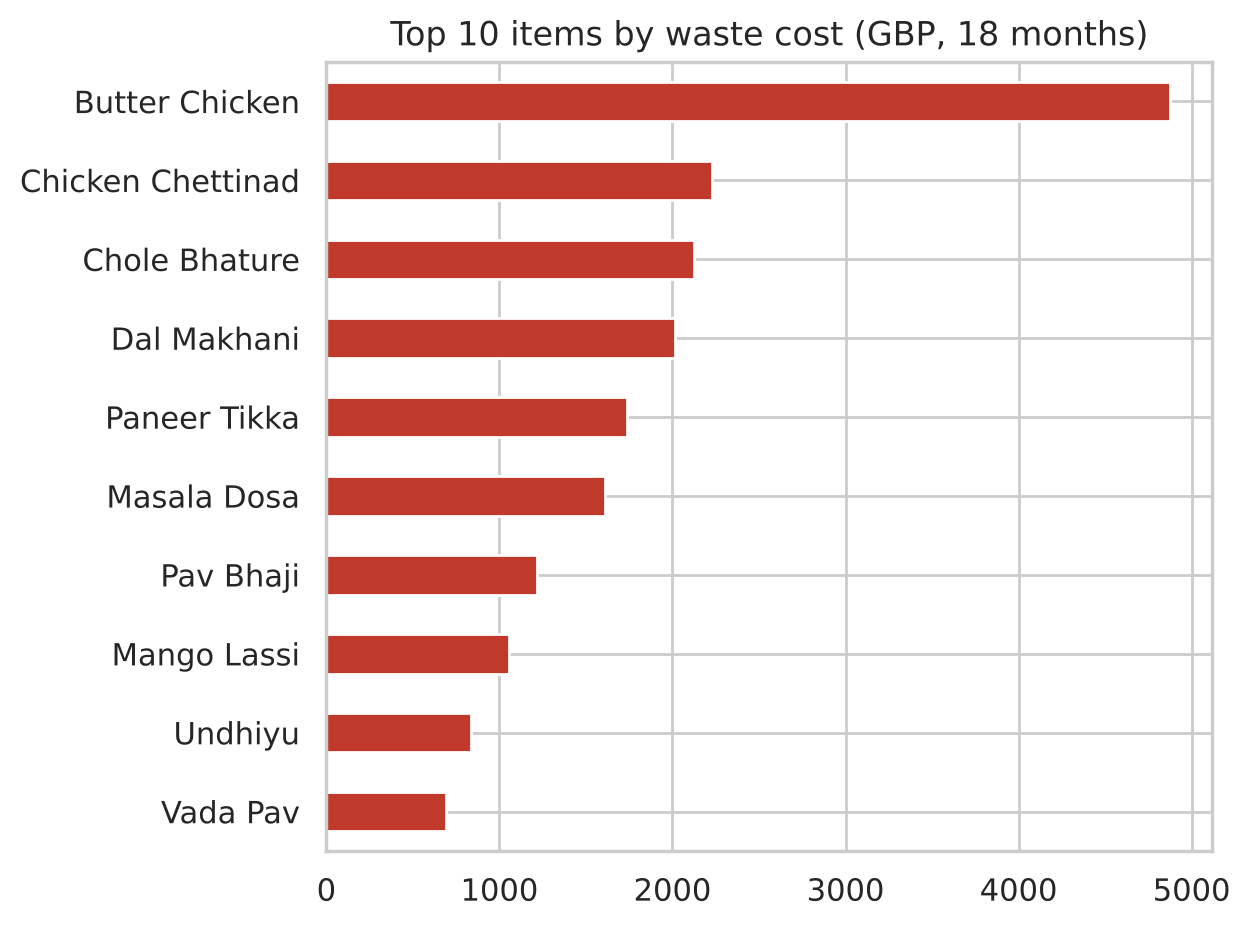

Total waste cost: GBP 22,644, waste rate 7.0%


,waste_cost,wasted,prepared,waste_rate_%
item_name,,,,
Butter Chicken,4876.2,1161,13645,8.5
Chicken Chettinad,2228.0,557,7436,7.5
Chole Bhature,2121.6,884,8729,10.1
Dal Makhani,2013.9,959,11214,8.6
Paneer Tikka,1739.1,561,9444,5.9
Masala Dosa,1611.2,848,12397,6.8
Pav Bhaji,1216.8,676,10184,6.6
Mango Lassi,1056.0,960,14749,6.5


In [7]:
fresh = df[df["shelf_life"] == "Same day"]
waste = fresh.groupby("item_name").agg(waste_cost=("waste_cost_gbp", "sum"), wasted=("wasted_qty", "sum"),
                                       prepared=("prepared_qty", "sum"))
waste["waste_rate_%"] = (100 * waste["wasted"] / waste["prepared"]).round(1)
ax = waste["waste_cost"].sort_values().tail(10).plot.barh(color="#c0392b")
ax.set(title="Top 10 items by waste cost (GBP, 18 months)", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_waste_by_item.png", dpi=120); plt.show()
print(f"Total waste cost: GBP {fresh['waste_cost_gbp'].sum():,.0f}, waste rate {fresh['wasted_qty'].sum() / fresh['prepared_qty'].sum():.1%}")
waste.sort_values("waste_cost", ascending=False).head(8)

## 3.6 Stockouts

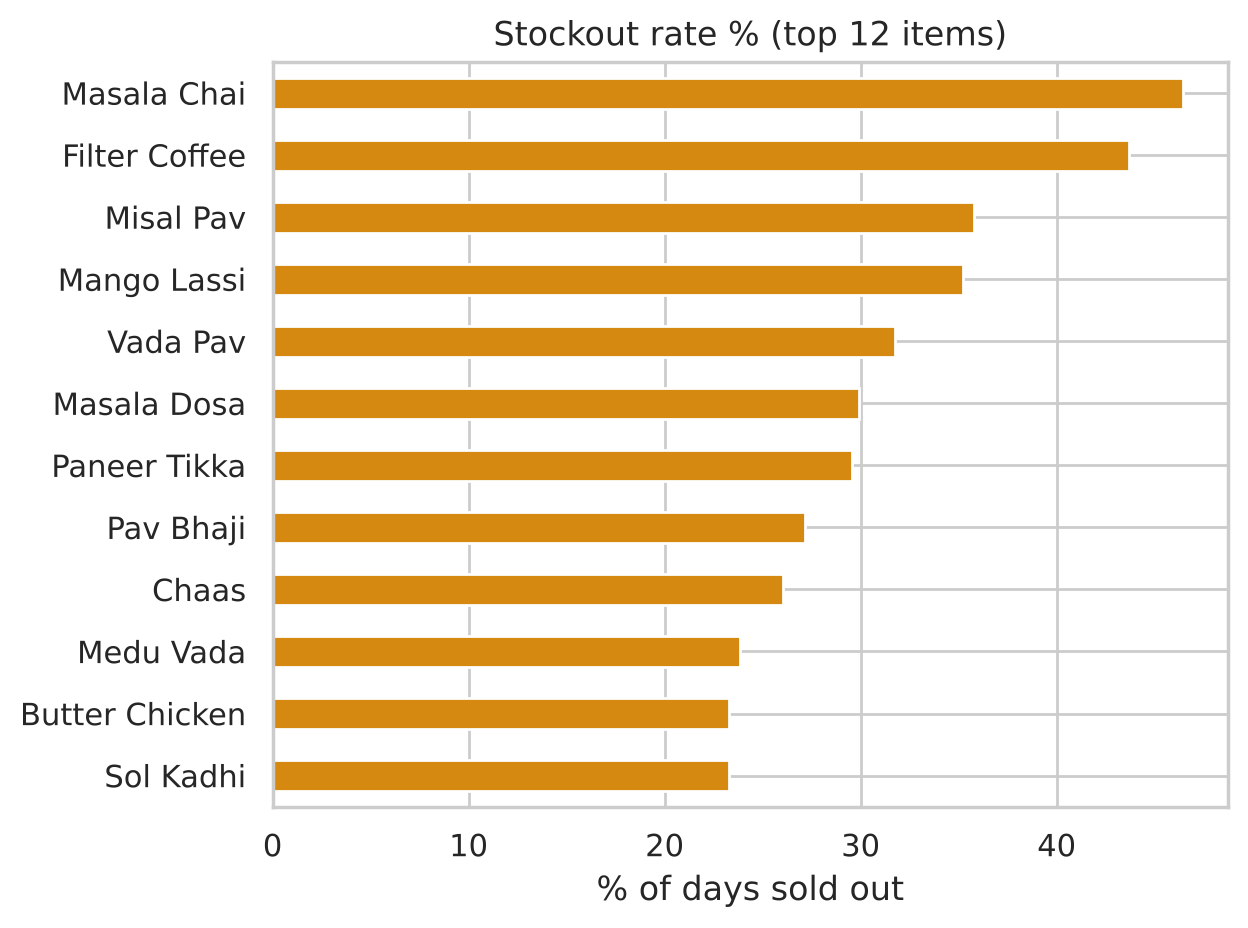

In [8]:
so = df.groupby("item_name")["stockout"].apply(lambda s: 100 * (s == "Yes").mean()).sort_values()
ax = so.tail(12).plot.barh(color="#d68910")
ax.set(title="Stockout rate % (top 12 items)", xlabel="% of days sold out", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_stockouts.png", dpi=120); plt.show()

## 3.7 Hypothesis tests
A **hypothesis test** checks if a difference is real or could just be luck.
- **p-value** = the chance of seeing a difference this big if there were really NO difference.
- Rule of thumb: **p < 0.05** means the difference is statistically significant.
- Welch's t-test compares two averages. ANOVA compares 3+ groups. Chi-square compares counts.

In [9]:
def welch(a, b):  # compare two averages without assuming equal spread
    r = stats.ttest_ind(a, b, equal_var=False)
    return round(a.mean(), 1), round(b.mean(), 1), f"{r.pvalue:.2e}"

guj = df[df["cuisine"] == "Gujarati"].groupby(["date", "festival"], as_index=False)["sold_qty"].sum()
results = pd.DataFrame([
    ("H1: Saturdays sell more than Mondays", *welch(daily.loc[daily.day_of_week == "Saturday", "sold"],
                                                       daily.loc[daily.day_of_week == "Monday", "sold"])),
    ("H2: Cricket days sell more bar drinks", *welch(bar.loc[bar.is_cricket == 1, "sold_qty"],
                                                        bar.loc[bar.is_cricket == 0, "sold_qty"])),
    ("H3: Navratri boosts Gujarati dishes", *welch(guj.loc[guj.festival == "Navratri", "sold_qty"],
                                                      guj.loc[guj.festival == "None", "sold_qty"])),
], columns=["Hypothesis", "Group A avg", "Group B avg", "p-value"])
anova_p = stats.f_oneway(*[g["sold"] for _, g in daily.groupby("weather")]).pvalue
chi_p = stats.chi2_contingency(pd.crosstab(df["is_weekend"], df["stockout"]))[1]
print(f"H4: Weather changes total daily sales (ANOVA): p = {anova_p:.2e}")
print(f"H5: Stockouts happen more at weekends (chi-square): p = {chi_p:.2f}")
results

H4: Weather changes total daily sales (ANOVA): p = 1.13e-04
H5: Stockouts happen more at weekends (chi-square): p = 0.62


,Hypothesis,Group A avg,Group B avg,p-value
0,H1: Saturdays sell more than Mondays,535.3,272.7,1.93e-74
1,H2: Cricket days sell more bar drinks,122.1,70.1,3.68e-05
2,H3: Navratri boosts Gujarati dishes,69.5,42.3,8.79e-04


## 3.8 Business insights
1. **Weekends drive the business.** Saturday sells about 2x a Monday (535 vs 273 portions, p < 0.001).
2. **Punjabi dishes earn the most** (over a third of revenue). Food is about 74% of revenue, drinks 26%.
3. **Waste is about 7% of fresh food prepared**, in line with the public Kaggle benchmark (6.9%).
   Butter Chicken alone wasted about GBP 4,900: high price and a generous buffer.
4. **India cricket matches nearly double bar sales** (122 vs 70 drinks a day, p < 0.001).
5. **Navratri lifts Gujarati dishes by about 64%** (p < 0.001). Festivals affect cuisines differently,
   so one "busy day" rule for the whole menu doesn't work.
6. **Hot drinks run out most** (chai 46% of days, filter coffee 44%). Cold days push demand above what the chef preps.
7. **Weekend stockouts are NOT higher than weekday ones (p = 0.62).** The chef already plans for weekends.
   Stockouts come from things the chef can't see coming: **weather and cricket**.
   👉 This is the business case for the AI: it learns those hidden effects.
8. ⚠️ **Stockouts hide true demand.** Mango Lassi sells about the same on warm and mild days because it
   keeps selling out. Sales data under-states real demand, so the model must correct for it (Phase 5).